In [ ]:
import numpy as np
from sklearn.naive_bayes import MultinomialNB,GaussianNB,BernoulliNB
from sklearn.metrics import accuracy_score,confusion_matrix,recall_score,f1_score
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split


In [ ]:
import pandas as pd
data=pd.read_csv("student_feedback_dataset.csv")
data

,student_id,department,subject_name,feedback_text,preprocessed_text,sentiment_label,sarcasm_flag,emotion_tag,feedback_type,subject_specific_context,response_required
0,STU0001,CIVIL,Concrete Tech,Attack medical dog technology top several insi...,attack medical dog technology top several insi...,negative,0,anger,Infrastructure,Project-Based,1
1,STU0002,CIVIL,Concrete Tech,Wait worry speak program child past beautiful ...,wait worry speak program child past beautiful ...,positive,0,anger,Infrastructure,Lab-Intensive,0
2,STU0003,BIO,Genetics,Bank those report box your treatment accept in...,bank those report box your treatment accept in...,neutral,0,sadness,Academic,Project-Based,1
3,STU0004,ME,Fluid Mechanics,Can character million listen right amount ask ...,can character million listen right amount ask ...,positive,0,joy,Academic,Theory-Heavy,0
4,STU0005,ME,Fluid Mechanics,Good cost political street dream finish figure.,good cost political street dream finish figure,negative,0,surprise,Academic,Theory-Heavy,1
...,...,...,...,...,...,...,...,...,...,...,...
1218,STU1219,CS,Data Structures,Left tell power small they actually be people ...,left tell power small they actually be people ...,neutral,0,fear,Academic,Lab-Intensive,0
1219,STU1220,CS,Data Structures,Today store office big stock future forget.,today store office big stock future forget,neutral,0,surprise,Instructor,Theory-Heavy,1
1220,STU1221,CIVIL,Concrete Tech,Up occur strategy what create education condit...,up occur strategy what create education condit...,positive,0,surprise,Academic,Project-Based,1
1221,STU1222,CIVIL,Concrete Tech,Social several difference certain ok course fa...,social several difference certain ok course fa...,positive,0,neutral,Academic,Lab-Intensive,1


In [ ]:
le=LabelEncoder()
x=le.fit_transform(data["sentiment_label"])
y=le.fit_transform(data["emotion_tag"])

In [ ]:
x = data["sentiment_label"]
y = data["emotion_tag"]

In [ ]:
x


,sentiment_label
0,negative
1,positive
2,neutral
3,positive
4,negative
...,...
1218,neutral
1219,neutral
1220,positive
1221,positive


In [ ]:
y


,emotion_tag
0,anger
1,anger
2,sadness
3,joy
4,surprise
...,...
1218,fear
1219,surprise
1220,surprise
1221,neutral


In [ ]:
accuracy=accuracy_score(x,y)

In [ ]:
cm=confusion_matrix(x,y)

In [ ]:
print("confusion matrix")
print(cm)

confusion matrix
[[ 0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0]
 [61 57 64  0 62  0 57 65]
 [63 66 55  0 61  0 59 64]
 [70 82 86  0 85  0 93 73]
 [ 0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0]]


In [ ]:
print("accuracy score")
print(accuracy)

accuracy score
0.04987735077677841


In [ ]:
x_train,y_train,x_test,y_test= train_test_split(x,y,test_size=0.2)

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

text=data['feedback_text']
text

,feedback_text
0,Attack medical dog technology top several insi...
1,Wait worry speak program child past beautiful ...
2,Bank those report box your treatment accept in...
3,Can character million listen right amount ask ...
4,Good cost political street dream finish figure.
...,...
1218,Left tell power small they actually be people ...
1219,Today store office big stock future forget.
1220,Up occur strategy what create education condit...
1221,Social several difference certain ok course fa...


In [ ]:
vectorizer=CountVectorizer()
x=vectorizer.fit_transform(text)

In [ ]:
y=data['sentiment_label']
le=LabelEncoder()
y=le.fit_transform(y)
y

array([0, 2, 1, ..., 2, 2, 1])

In [ ]:

model=MultinomialNB()
model.fit(x,y)

MultinomialNB()

In [ ]:
sentiment_label=input("Enter your sentiment:")
ans=vectorizer.transform([sentiment_label])
model.predict(ans)
le.inverse_transform(model.predict(ans))

Enter your sentiment:anger


array(['positive'], dtype=object)

In [ ]:
y_pred=model.predict(x)
cm=confusion_matrix(y,y_pred)
cm

array([[290,  33,  43],
       [ 35, 280,  53],
       [ 44,  50, 395]])

In [ ]:
accuracy=accuracy_score(y,y_pred)
accuracy

0.7890433360588717

In [ ]:
f1=f1_score(y,y_pred,average='weighted')
f1

0.788982329321468

In [ ]:
recall=recall_score(y,y_pred,average='weighted')
recall

0.7890433360588717

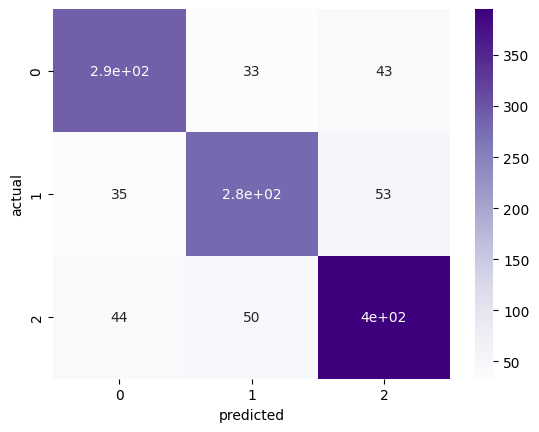

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.heatmap(cm,annot=True,cmap="Purples")
plt.xlabel("predicted")
plt.ylabel("actual")
plt.show()